# 04 Figures for the data section and paper-style tables

Reads only the final files written by `01_olivine`, `02_glass` and `03_laicpms` (run those first). Excluded analyses and flagged values are left out of the figures; the tables keep everything that is reportable, with notes.

In [1]:
# --- config ---
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from openpyxl.utils import get_column_letter

OUT, FIG = Path("outputs"), Path("figures/report")
FIG.mkdir(parents=True, exist_ok=True)
KD, FE2 = (0.27, 0.33), (0.85, 1.00)       # olivine-melt Fe-Mg Kd 0.30 ± 0.03 (Roeder and Emslie 1970); Fe2+/total Fe of the melt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9})

gl = pd.read_excel(OUT / "glass_final.xlsx", sheet_name=None)
ol = pd.read_excel(OUT / "olivine_final.xlsx", sheet_name=None)
la = pd.read_excel(OUT / "laicpms_final.xlsx", sheet_name=None)
laqc = pd.read_excel(OUT / "laicpms_standards_QC.xlsx", sheet_name=None, index_col=0)
gs, gm = gl["samples corrected"], gl["sample means"].set_index("Sample")
os_, og = ol["samples corrected"], ol["grain means"].set_index(["Sample", "Grain"])

## Glass: Harker diagram

Spots (small, transparent) and sample means ± 2SD (squares). Excluded analyses (No. 49 and 65) are not plotted.

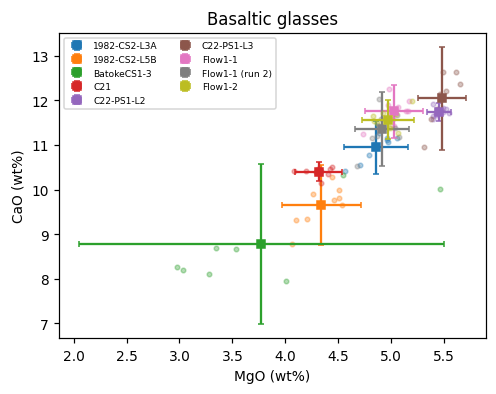

In [2]:
g = gs[~gs.exclude]
fig, ax = plt.subplots(figsize=(5, 3.6))
for i, (s, d) in enumerate(g.groupby("Sample")):
    ax.plot(d.MgO, d.CaO, "o", ms=3, alpha=0.35, color=f"C{i}")
    m = gm.loc[s]
    ax.errorbar(m.MgO, m.CaO, xerr=m.MgO_2SD, yerr=m.CaO_2SD, fmt="s", ms=5, capsize=2, color=f"C{i}",
                label=s.replace("UnknA-", ""))
ax.set(xlabel="MgO (wt%)", ylabel="CaO (wt%)", title="Basaltic glasses")
ax.legend(fontsize=6, ncol=2)
fig.savefig(FIG / "glass_MgO_CaO.png"); plt.show()

## Olivine: Fo against NiO, and equilibrium with the C21 glass

Grain means ± 2SD. The grey band is the Fo of an olivine in Fe-Mg equilibrium with the mean C21 glass from `02_glass`, for Kd = 0.30 ± 0.03 and 85 to 100 % of the iron as Fe²⁺ (FeO in the glass is total iron). This assumes the C21 glass and the C21MI olivines come from the same sample.

Fo in equilibrium with glass C21: 64.9 to 72.7; C21MI olivine grains: Fo 78.6 to 85.6


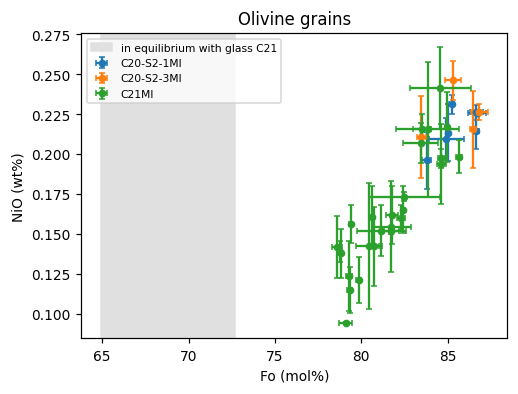

In [3]:
c21 = gm.loc["UnknA-C21"]
r = (c21.FeO / 71.844) / (c21.MgO / 40.304)                            # molar FeO/MgO of the glass, all Fe as FeO
fo_eq = lambda kd, f: 100 / (1 + kd * f * r)
lo, hi = fo_eq(KD[1], FE2[1]), fo_eq(KD[0], FE2[0])
c21ol = og.loc["UnkA-C21MI", "Fo"]
print(f"Fo in equilibrium with glass C21: {lo:.1f} to {hi:.1f}; C21MI olivine grains: Fo {c21ol.min():.1f} to {c21ol.max():.1f}")

fig, ax = plt.subplots(figsize=(5, 3.6))
ax.axvspan(lo, hi, color="0.88", label="in equilibrium with glass C21")
for i, (s, d) in enumerate(og.groupby(level="Sample")):
    ax.errorbar(d.Fo, d.NiO, xerr=d.Fo_2SD, yerr=d.NiO_2SD, fmt="o", ms=4, capsize=2, color=f"C{i}", label=s.replace("UnkA-", ""))
ax.set(xlabel="Fo (mol%)", ylabel="NiO (wt%)", title="Olivine grains")
ax.legend(fontsize=7)
fig.savefig(FIG / "olivine_Fo_NiO.png"); plt.show()

## Paper-style tables

One sheet per dataset: sample (or grain, or inclusion) averages as mean ± 2SD with n, and the standards measured in the same session next to their reference values. Numbers are rounded to the precision of their 2SD.

In [4]:
def pm(m, s=np.nan):
    if pd.isna(m): return ""
    if pd.isna(s) or s == 0:
        return f"{m:.3g}" if abs(m) < 1000 else f"{m:.0f}"
    d = int(np.clip(1 - np.floor(np.log10(abs(s))), 0, 4))
    return f"{m:.{d}f} ± {s:.{d}f}"

def table(means, cols, n_col="n"):
    return pd.DataFrame({"n": means[n_col].astype(int), **{c: [pm(m, s) for m, s in zip(means[c], means.get(f"{c}_2SD", np.nan))] for c in cols}})

def std_rows(sc, refs, cols, label):
    rows = {}
    for s, d in sc.groupby("Sample"):
        rows[f"{s} measured ({label})"] = {"n": len(d), **{c: pm(d[c].mean(), 2 * d[c].std()) for c in cols}}
        if s in refs.index:
            rows[f"{s} reference"] = {"n": "", **{c: f"{refs.at[s, c]:.4g}" if pd.notna(refs.at[s, c]) else "" for c in cols}}
    return pd.DataFrame(rows).T

GOX = ["SiO2", "TiO2", "Al2O3", "FeO", "MnO", "MgO", "CaO", "Na2O", "K2O", "P2O5", "SO3", "Cl", "F", "Total"]
t_gl = pd.concat([table(gm, GOX), std_rows(gl["standards corrected"], gl["references"].set_index(gl["references"].columns[0]),
                                           GOX[:-1], "corrected")])
OOX = ["SiO2", "Al2O3", "Cr2O3", "FeO", "MnO", "MgO", "CaO", "NiO", "Total", "Fo"]
t_ol = pd.concat([table(og.droplevel("Sample"), OOX), std_rows(ol["standards corrected"],
                  ol["references"].set_index(ol["references"].columns[0]), OOX[:-2], "corrected")])

im = la["inclusion means"].set_index(["group", "inclusion"])
flags = la["element flags"].set_index(la["element flags"].columns[0])
LEL = [c for c in im.columns if c not in ("n", "Pb_contaminated")]
t_la = pd.DataFrame({"n": im.n.astype(int), **{c: [pm(v) for v in im[c]] for c in LEL}})
t_la.loc[im.Pb_contaminated.values, "Pb208"] = t_la.loc[im.Pb_contaminated.values, "Pb208"] + " c"
t_la.index = [f"{g} {i}" for g, i in t_la.index]
for name, key in [("BCR-2G", "BCR-2G"), ("KL2 (control)", "KL2 control")]:
    q = laqc[key]
    t_la.loc[f"{name} measured"] = {"n": int(q.n.max()), **{c: pm(q.at[c, "average"], q.at[c, "2SD"]) for c in LEL}}
    t_la.loc[f"{name} reference"] = {"n": "", **{c: pm(q.at[c, "reference"], q.at[c, "reference_unc_95"]) for c in LEL}}
t_la.columns = ["n"] + [f"{c}{' *' if c in flags.index[flags.flag.notna()] else ''}" for c in LEL]

NOTES = {
    "Glass (EPMA)": ["Mean ± 2SD in wt%; n = number of spots. Corrected with the calibration standard of each oxide (VGA99; Scapolite for SO3 and Cl; KE3 for F; VG-2 for MnO).",
                     "Excluded: analyses No. 49 and 65; SO3 of No. 32 and Cl of No. 70.",
                     "UnknA-Flow1-1 (run 2): same sample measured twice under one name; both runs agree within 2SD."],
    "Olivine (EPMA)": ["Mean ± 2SD in wt%; Fo in mol%; n = number of spots per grain. Corrected with SC-Olivine.",
                       "Cr2O3 is below the detection limit (~0.008 wt%) in 36 of 113 analyses."],
    "Melt inclusions (LA-ICP-MS)": ["Concentrations in ppm (µg/g); repeat analyses of one inclusion averaged (n). Detrended with the KL2 bracketing standard.",
                                    "* element flagged: 2RSD on KL2 > 20 % or deviation on BCR-2G > 15 % (see QC table).",
                                    "c: Pb/Pb* > 5, probable Pb contamination; reported but not interpreted.",
                                    "Reference values: GeoReM (Standards.xlsx) ± 95 % uncertainty."],
}
with pd.ExcelWriter(OUT / "paper_tables.xlsx", engine="openpyxl") as xw:
    for sheet, t in [("Glass (EPMA)", t_gl), ("Olivine (EPMA)", t_ol), ("Melt inclusions (LA-ICP-MS)", t_la)]:
        t.to_excel(xw, sheet_name=sheet)
        ws = xw.sheets[sheet]
        for k, note in enumerate(NOTES[sheet]):
            ws.cell(row=len(t) + 3 + k, column=1, value=note)
        for j in range(1, t.shape[1] + 2):
            ws.column_dimensions[get_column_letter(j)].width = 30 if j == 1 else 15
print({k: v.shape for k, v in {"glass": t_gl, "olivine": t_ol, "melt inclusions": t_la}.items()})
t_gl.head(4)

{'glass': (17, 15), 'olivine': (39, 11), 'melt inclusions': (45, 41)}


,n,SiO2,TiO2,Al2O3,FeO,MnO,MgO,CaO,Na2O,K2O,P2O5,SO3,Cl,F,Total
1982-CS2-L3A,9,45.74 ± 0.90,3.914 ± 0.095,15.22 ± 0.18,13.33 ± 0.83,0.220 ± 0.073,4.86 ± 0.30,10.94 ± 0.59,3.1 ± 1.8,1.74 ± 0.15,0.66 ± 0.11,0.036 ± 0.038,0.121 ± 0.013,0.141 ± 0.055,100.06 ± 0.60
1982-CS2-L5B,9,45.90 ± 0.73,3.80 ± 0.14,15.06 ± 0.60,13.7 ± 1.7,0.257 ± 0.073,4.34 ± 0.37,9.65 ± 0.89,4.70 ± 0.79,2.07 ± 0.26,0.732 ± 0.051,0.035 ± 0.019,0.130 ± 0.029,0.203 ± 0.084,100.57 ± 0.91
UnknA-BatokeCS1-3,8,48.0 ± 3.4,3.07 ± 0.23,17.7 ± 1.4,10.1 ± 1.1,0.170 ± 0.052,3.8 ± 1.7,8.8 ± 1.8,5.4 ± 1.3,2.36 ± 0.49,1.23 ± 0.14,0.017 ± 0.022,0.07 ± 0.14,0.263 ± 0.089,100.96 ± 0.86
UnknA-C21,9,44.59 ± 0.88,3.751 ± 0.064,15.49 ± 0.67,12.6 ± 1.2,0.240 ± 0.025,4.31 ± 0.23,10.40 ± 0.21,4.67 ± 0.11,2.192 ± 0.079,0.979 ± 0.075,0.111 ± 0.037,0.125 ± 0.045,0.18 ± 0.13,99.9 ± 2.0
